# 02 — Preprocessing Pipeline
Clean → Encode → Scale → Feature Selection → PCA → t-SNE

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, pickle, os
if os.path.basename(os.getcwd())=='notebooks': os.chdir('..')
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
SEED=42; RAW='data/raw'; PROC='data/processed'; MOD='models'; CH='charts'
for d in [PROC,MOD,f'{CH}/pca_tsne']: os.makedirs(d,exist_ok=True)
print(f'CWD: {os.getcwd()}')

CWD: /home/ashutosh/Desktop/NO-AI-USE/ml_projects/09_logistics_multiclass_intelligence


## 1. Load & Clean

In [2]:
df=pd.read_csv(f'{RAW}/DataCoSupplyChainDataset.csv',encoding='latin-1',low_memory=False)
TARGET='Delivery Status'
DROP=['Late_delivery_risk','Customer Email','Customer Password','Customer Fname',
      'Customer Lname','Customer Street','Customer City','Customer State','Customer Zipcode',
      'Order City','Order State','Order Region','Order Country','Order Zipcode',
      'Customer Id','Order Customer Id','Order Id','Product Description','Product Image',
      'Product Status','Category Id','Department Id','Product Card Id','Product Category Id',
      'Order Item Id','Order Item Cardprod Id','order date (DateOrders)','shipping date (DateOrders)',
      'Latitude','Longitude','Order Status']
df.drop(columns=[c for c in DROP if c in df.columns],inplace=True)
df.dropna(subset=[TARGET],inplace=True)
print(f'Cleaned: {df.shape}')

Cleaned: (180519, 22)


In [3]:
# Encode target
le_target=LabelEncoder()
y=pd.Series(le_target.fit_transform(df[TARGET]),name='target')
CLASS_NAMES=le_target.classes_.tolist()
X=df.drop(columns=[TARGET])
print(f'Classes: {CLASS_NAMES}')
print(f'X:{X.shape} y:{y.shape}')

Classes: ['Advance shipping', 'Late delivery', 'Shipping canceled', 'Shipping on time']
X:(180519, 21) y:(180519,)


## 2. Impute Missing

In [4]:
num_cols=X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols=X.select_dtypes(include=['object','category']).columns.tolist()
print(f'Num:{len(num_cols)} Cat:{len(cat_cols)}')
X[num_cols]=SimpleImputer(strategy='median').fit_transform(X[num_cols])
if cat_cols:
    X[cat_cols]=SimpleImputer(strategy='most_frequent').fit_transform(X[cat_cols])
print(f'Nulls: {X.isnull().sum().sum()}')

Num:13 Cat:8


Nulls: 0


## 3. Encode Categoricals

In [5]:
label_encoders={}
for col in cat_cols:
    if X[col].nunique()<=15:
        le=LabelEncoder(); X[col]=le.fit_transform(X[col].astype(str))
        label_encoders[col]=le
    else:
        freq=X[col].value_counts(normalize=True).to_dict()
        X[col]=X[col].map(freq).fillna(0)
pickle.dump(label_encoders,open(f'{MOD}/label_encoders.pkl','wb'))
print(f'Encoded {len(cat_cols)} cols. X:{X.shape}')

Encoded 8 cols. X:(180519, 21)


## 4. Feature Selection

In [6]:
# Correlation removal >0.95
corr_m=X.corr().abs()
upper=corr_m.where(np.triu(np.ones(corr_m.shape),k=1).astype(bool))
drop_corr=[c for c in upper.columns if any(upper[c]>0.95)]
X.drop(columns=drop_corr,inplace=True,errors='ignore')
print(f'Correlation drop: {len(drop_corr)}')

# Variance threshold
vt=VarianceThreshold(threshold=0.01)
X_vt=pd.DataFrame(vt.fit_transform(X),columns=[c for c,k in zip(X.columns,vt.get_support()) if k],index=X.index)
print(f'Variance drop: {X.shape[1]-X_vt.shape[1]}'); X=X_vt

# RFE top 20
N=min(20,X.shape[1])
print(f'RFE selecting top {N}...')
rfe=RFE(RandomForestClassifier(n_estimators=50,max_depth=8,random_state=SEED,n_jobs=-1),n_features_to_select=N,step=3)
rfe.fit(X,y)
feats=[c for c,k in zip(X.columns,rfe.support_) if k]
X=X[feats]
print(f'Selected {len(feats)}: {feats}')

Correlation drop: 5
Variance drop: 2
RFE selecting top 14...


Selected 14: ['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Customer Country', 'Customer Segment', 'Department Name', 'Market', 'Order Item Discount', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Shipping Mode']


## 5. Scale

In [7]:
scaler=MinMaxScaler()
X_scaled=pd.DataFrame(scaler.fit_transform(X),columns=feats,index=X.index)
pickle.dump(scaler,open(f'{MOD}/scaler.pkl','wb'))
pickle.dump(feats,open(f'{MOD}/feature_columns.pkl','wb'))
print(f'Scaled: {X_scaled.shape}')

Scaled: (180519, 14)


## 6. PCA

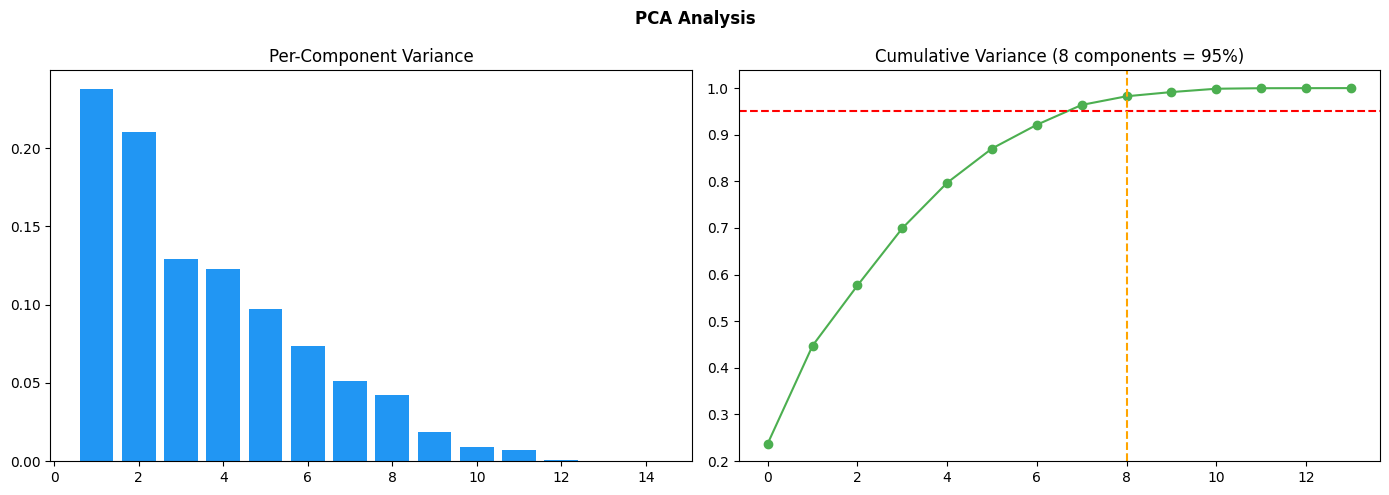

PCA 95%: (180519, 8)


In [8]:
pca_full=PCA(random_state=SEED).fit(X_scaled)
cumvar=np.cumsum(pca_full.explained_variance_ratio_)
n95=np.argmax(cumvar>=0.95)+1
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,5))
a1.bar(range(1,len(cumvar)+1),pca_full.explained_variance_ratio_,color='#2196F3')
a1.set_title('Per-Component Variance')
a2.plot(cumvar,'o-',color='#4CAF50'); a2.axhline(0.95,color='red',ls='--'); a2.axvline(n95,color='orange',ls='--')
a2.set_title(f'Cumulative Variance ({n95} components = 95%)')
plt.suptitle('PCA Analysis',fontweight='bold'); plt.tight_layout()
plt.savefig(f'{CH}/pca_tsne/05_pca_variance.png',dpi=150,bbox_inches='tight'); plt.show()

pca_95=PCA(n_components=0.95,random_state=SEED)
X_pca=pd.DataFrame(pca_95.fit_transform(X_scaled),columns=[f'PC{i+1}' for i in range(pca_95.n_components_)])
pickle.dump(pca_95,open(f'{MOD}/pca_model.pkl','wb'))
print(f'PCA 95%: {X_pca.shape}')

## 7. t-SNE

t-SNE on 5000 samples...


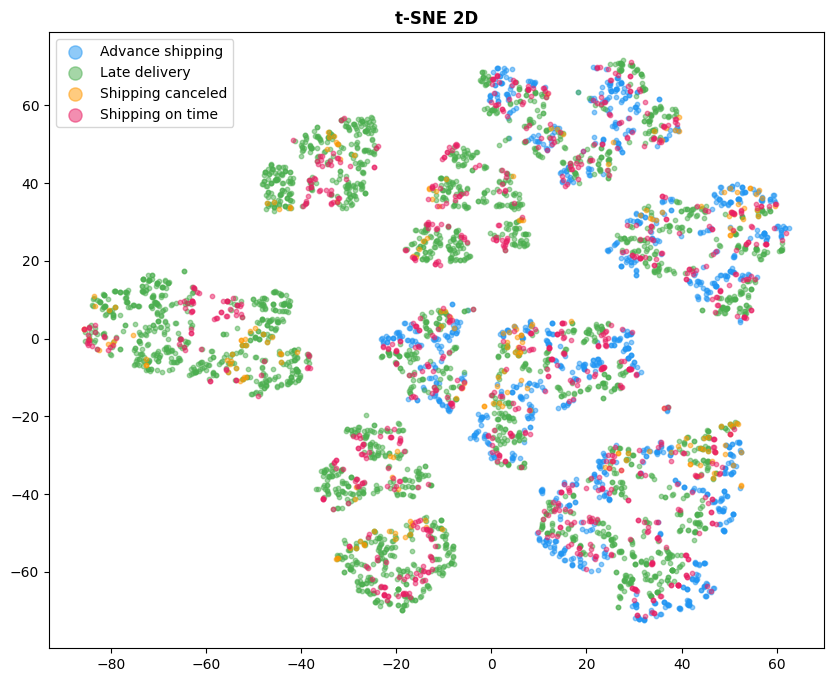

In [9]:
sn=min(5000,len(X_scaled))
idx=np.random.RandomState(SEED).choice(len(X_scaled),sn,replace=False)
print(f't-SNE on {sn} samples...')
X_tsne=TSNE(2,perplexity=30,random_state=SEED).fit_transform(X_scaled.iloc[idx])
fig,ax=plt.subplots(figsize=(10,8))
for ci,name in enumerate(CLASS_NAMES):
    m=y.iloc[idx]==ci
    ax.scatter(X_tsne[m,0],X_tsne[m,1],label=name,alpha=0.5,s=10,color=['#2196F3','#4CAF50','#FF9800','#E91E63'][ci])
ax.set_title('t-SNE 2D',fontweight='bold'); ax.legend(markerscale=3)
plt.savefig(f'{CH}/pca_tsne/06_tsne.png',dpi=150,bbox_inches='tight'); plt.show()

## 8. Save

In [10]:
X_scaled.to_csv(f'{PROC}/X_processed.csv',index=False)
y.to_csv(f'{PROC}/y_target.csv',index=False)
X_pca.to_csv(f'{PROC}/X_pca_95.csv',index=False)
pickle.dump(CLASS_NAMES,open(f'{MOD}/class_names.pkl','wb'))
pickle.dump(le_target,open(f'{MOD}/label_encoder.pkl','wb'))
print(f'Saved: X:{X_scaled.shape} PCA:{X_pca.shape} y:{y.shape}')

Saved: X:(180519, 14) PCA:(180519, 8) y:(180519,)
